# code_112 · Selective state scans and reference attention under length shift

**Book:** section 22.5. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_22_GUIDE.md), [run evidence](../CHAPTER_22_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_112).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2312;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2312


<a id="state-space-contract"></a>
 ## A bounded reference experiment, not a full Mamba benchmark
 A marked vibration-amplitude observation must remain available through later background noise. Fit independent train48/development24 episodes of length32; evaluate the same 48 new episodes at prefixes32/128/512. The marked event stays inside the first sixteen observations, so longer prefixes add distractors to the same episode. All models predict the latest marked value at every causal query. Compare an original selective diagonal state model (627 parameters), a reference causal Transformer block (633), and a static-control state ablation (339). They receive the same two learning rates, 120-update budgets and development checkpoint rule. Main computation and all CPU profiles use float32. The state model implements its stated recurrence and exact diagonal zero-order-hold discretization; it does not execute S4, Mamba, Mamba-2 or Mamba-3 optimized architectures.


,model,length,last_query_MSE,all_query_MSE,parameters,selected_rate,best_step
0,Selective scan,32,0.018866,0.007102,627,0.01,120
1,Selective scan,128,0.380159,0.156783,627,0.01,120
2,Selective scan,512,0.534934,0.425662,627,0.01,120
3,Reference attention,32,0.006982,0.004858,633,0.01,120
4,Reference attention,128,0.702160,0.259761,633,0.01,120
5,Reference attention,512,1.001933,0.508849,633,0.01,120
6,Static scan,32,0.077329,0.026917,339,0.01,120
7,Static scan,128,0.521418,0.252412,339,0.01,120
8,Static scan,512,0.512821,0.474030,339,0.01,120


The hand-coded marker-memory rule has zero error by construction.


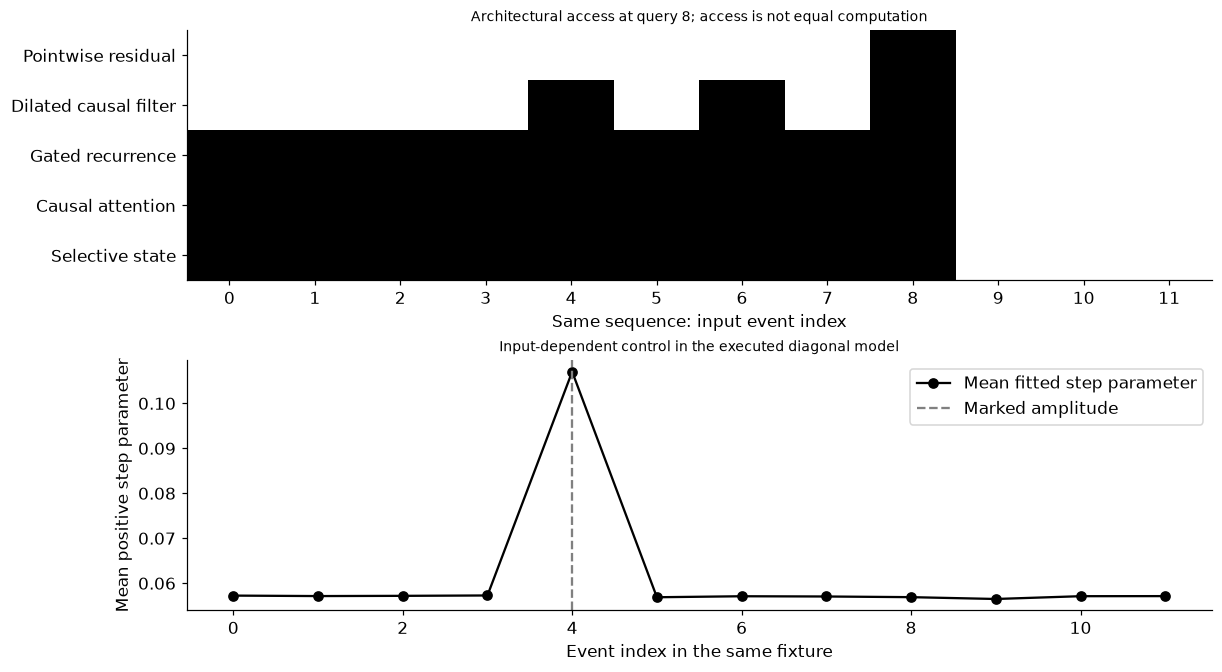

In [2]:
import copy
MODEL_SOURCE=r"""
import math,torch
from torch import nn
class DiagonalSSM(nn.Module):
    def __init__(self,selective=True,width=48):
        super().__init__();self.selective=selective;self.width=width;self.rate_raw=nn.Parameter(torch.zeros(width));self.value=nn.Linear(2,width);self.skip=nn.Linear(2,1)
        if selective:
            self.delta=nn.Linear(2,width);self.b=nn.Linear(2,width);self.c=nn.Linear(2,width);nn.init.zeros_(self.delta.weight);nn.init.constant_(self.delta.bias,-3.);nn.init.normal_(self.b.weight,std=.05);nn.init.constant_(self.b.bias,.1);nn.init.normal_(self.c.weight,std=.01);nn.init.constant_(self.c.bias,.1)
        else:
            self.delta=nn.Parameter(torch.full((width,),-3.));self.b=nn.Parameter(torch.full((width,),.1));self.c=nn.Parameter(torch.full((width,),.1))
    def forward(self,values,state=None,return_history=False):
        h=values.new_zeros(values.shape[0],self.width) if state is None else state;rate=nn.functional.softplus(self.rate_raw)+1e-4;outputs=[];states=[];retentions=[];deltas=[]
        for index in range(values.shape[1]):
            current=values[:,index];delta=nn.functional.softplus(self.delta(current) if self.selective else self.delta)+1e-4;b=self.b(current) if self.selective else self.b;c=self.c(current) if self.selective else self.c;alpha=torch.exp(-delta*rate);drive=-torch.expm1(-delta*rate)/rate;h=alpha*h+drive*b*self.value(current);outputs.append((c*h).sum(-1)/math.sqrt(self.width)+self.skip(current).squeeze(-1))
            if return_history:states.append(h);retentions.append(alpha.expand_as(h));deltas.append(delta.expand_as(h))
        history={'states':torch.stack(states,1),'retentions':torch.stack(retentions,1),'deltas':torch.stack(deltas,1)} if return_history else {}
        return torch.stack(outputs,1),h,history
def positions(length,reference):
    index=torch.arange(length,device=reference.device,dtype=reference.dtype)[:,None];frequency=torch.exp(torch.arange(0,8,2,device=reference.device,dtype=reference.dtype)*(-math.log(10000)/8));out=reference.new_zeros(length,8);out[:,0::2]=torch.sin(index*frequency);out[:,1::2]=torch.cos(index*frequency);return out
class ReferenceAttention(nn.Module):
    def __init__(self,incoming=2):
        super().__init__();self.input=nn.Linear(incoming,8);self.norm1=nn.LayerNorm(8);self.qkv=nn.Linear(8,24);self.output=nn.Linear(8,8);self.norm2=nn.LayerNorm(8);self.feedforward=nn.Sequential(nn.Linear(8,16),nn.GELU(),nn.Linear(16,8));self.head=nn.Linear(8,1)
    def forward(self,values,state=None,return_history=False):
        if state is not None:raise ValueError('This reference attention model has no recurrent-cache interface')
        batch,length,_=values.shape;z=self.input(values)+positions(length,values);q,k,v=self.qkv(self.norm1(z)).reshape(batch,length,3,2,4).permute(2,0,3,1,4);score=q@k.transpose(-1,-2)/2.;forbidden=torch.triu(torch.ones(length,length,dtype=torch.bool,device=values.device),1);weights=torch.softmax(score.masked_fill(forbidden,-torch.inf),-1);mixed=(weights@v).transpose(1,2).reshape(batch,length,8);h=z+self.output(mixed);h=h+self.feedforward(self.norm2(h));return self.head(h).squeeze(-1),None,{'attention':weights} if return_history else {}
"""
exec(MODEL_SOURCE)
def generate(count,length,marker_upper=16):
    values=rng.normal(0,.03,(count,length,2)).astype(np.float32);values[:,:,1]=0.;marked=rng.integers(1,min(marker_upper,length),count);amplitudes=rng.uniform(-1,1,count).astype(np.float32);values[np.arange(count),marked,0]=amplitudes;values[np.arange(count),marked,1]=1.;target=np.where(np.arange(length)[None,:]>=marked[:,None],amplitudes[:,None],0.).astype(np.float32);return torch.tensor(values,dtype=torch.float32),torch.tensor(target,dtype=torch.float32)
train_x,train_y=generate(48,32);dev_x,dev_y=generate(24,32);final_x,final_y=generate(48,512)
configurations={'Selective scan':lambda:DiagonalSSM(True),'Reference attention':ReferenceAttention,'Static scan':lambda:DiagonalSSM(False)};fitted={};selection=[];rows=[]
for name,constructor in configurations.items():
    candidates=[]
    for rate in [.005,.01]:
        torch.manual_seed(SEED);model=constructor().float();optimizer=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.001);best=float('inf');state=None
        for step in range(120):
            optimizer.zero_grad();prediction,_,_=model(train_x);loss=torch.mean((prediction-train_y)**2);loss.backward();optimizer.step()
            if (step+1)%10==0:
                model.eval()
                with torch.no_grad():prediction,_,_=model(dev_x);value=float(torch.mean((prediction-dev_y)**2))
                if value<best:best=value;state=copy.deepcopy(model.state_dict());best_step=step+1
        model.load_state_dict(state);model.eval();candidates.append((best,rate,best_step,model));selection.append({'model':name,'rate':rate,'development_MSE':best,'best_step':best_step})
    best,rate,best_step,model=min(candidates,key=lambda v:v[0]);fitted[name]=model
    for length in [32,128,512]:
        with torch.no_grad():prediction,_,_=model(final_x[:,:length]);last_mse=float(torch.mean((prediction[:,-1]-final_y[:,length-1])**2));query_mse=float(torch.mean((prediction-final_y[:,:length])**2))
        rows.append({'model':name,'length':length,'last_query_MSE':last_mse,'all_query_MSE':query_mse,'parameters':sum(p.numel() for p in model.parameters()),'selected_rate':rate,'best_step':best_step})
assert next(r['parameters'] for r in rows if r['model']=='Selective scan')==627 and next(r['parameters'] for r in rows if r['model']=='Reference attention')==633
# A known marker-copy rule is a privileged task-specific baseline, not a learned neural result.
memory=torch.zeros(48,dtype=torch.float32);rule=[]
for index in range(512):memory=torch.where(final_x[:,index,1]>0,final_x[:,index,0],memory);rule.append(memory)
rule=torch.stack(rule,1);torch.testing.assert_close(rule,final_y,atol=0,rtol=0)
# Constant-input diagonal discretization has the expected subdivision identity.
rate=torch.tensor(.7,dtype=torch.float64);delta=torch.tensor(.2,dtype=torch.float64);h0=torch.tensor(.2,dtype=torch.float64);b=torch.tensor(1.3,dtype=torch.float64);value=torch.tensor(.4,dtype=torch.float64)
def advance(h,dt):return torch.exp(-rate*dt)*h-torch.expm1(-rate*dt)/rate*b*value
torch.testing.assert_close(advance(h0,delta),advance(advance(h0,delta/2),delta/2),atol=1e-12,rtol=1e-12)
with torch.no_grad():
    whole,state,_=fitted['Selective scan'](final_x[:1,:128]);first,state,_=fitted['Selective scan'](final_x[:1,:64]);second,state,_=fitted['Selective scan'](final_x[:1,64:128],state);torch.testing.assert_close(whole,torch.cat([first,second],1),atol=1e-6,rtol=1e-6);stream_difference=float(torch.max(torch.abs(whole-torch.cat([first,second],1))))
    control_values=torch.tensor([[[.3,0.],[.3,1.]]],dtype=torch.float32);_,_,controls=fitted['Selective scan'](control_values,return_history=True);control_difference=float(torch.linalg.vector_norm(controls['deltas'][:,0]-controls['deltas'][:,1]))
# An untrained hybrid contract fixture: recurrent summaries at events3/7/11/15 attend causally.
class SummaryHybrid(nn.Module):
    def __init__(self):super().__init__();self.scan=DiagonalSSM(True);self.attention=ReferenceAttention(48)
    def forward(self,values):
        _,_,history=self.scan(values,return_history=True);return self.attention(history['states'][:,3::4])[0]
torch.manual_seed(SEED+20);hybrid=SummaryHybrid().float().eval();hybrid_input=final_x[:1,:16].clone();changed=hybrid_input.clone();changed[:,8:,0]+=1
with torch.no_grad():a=hybrid(hybrid_input);b=hybrid(changed);torch.testing.assert_close(a[:,:2],b[:,:2],atol=1e-6,rtol=1e-6)
RESULTS.update(comparisons=rows,selection=selection,source_episode_counts=[48,24,48],fit_length=32,paired_final_lengths=[32,128,512],exact_marker_rule_MSE=float(torch.mean((rule-final_y)**2)),streaming_max_difference=stream_difference,delta_marker_control_difference=control_difference,hybrid_prefix_max_difference=float(torch.max(torch.abs(a[:,:2]-b[:,:2]))),hybrid_summary_indices=[3,7,11,15],hybrid_untrained_parameters=sum(p.numel() for p in hybrid.parameters()),diagonal_subdivision_identity_checked=True,profile_batch=4,profile_dtype='float32',recurrent_state_bytes=4*48*4,materialized_attention_score_bytes=[{'length':length,'bytes':4*2*length*length*4} for length in [32,128,512]])
display(pd.DataFrame(rows));print('The hand-coded marker-memory rule has zero error by construction.')
fixture=final_x[:1,:12].clone();fixture[:,:,1]=0;fixture[:,4,1]=1;fixture[:,4,0]=.7
with torch.no_grad():_,_,history=fitted['Selective scan'](fixture,return_history=True)
access=np.zeros((5,12));access[0,8]=1;access[1,[4,6,8]]=1;access[2:,:9]=1
fig,axes=plt.subplots(2,1,figsize=(11,6));axes[0].imshow(access,cmap='Greys',vmin=0,vmax=1,aspect='auto');axes[0].set(yticks=range(5),yticklabels=['Pointwise residual','Dilated causal filter','Gated recurrence','Causal attention','Selective state'],xticks=range(12),xlabel='Same sequence: input event index',title='Architectural access at query 8; access is not equal computation')
axes[1].plot(history['deltas'][0].mean(1).numpy(),'o-',color='black',label='Mean fitted step parameter');axes[1].axvline(4,linestyle='--',color='.5',label='Marked amplitude');axes[1].set(xlabel='Event index in the same fixture',ylabel='Mean positive step parameter',title='Input-dependent control in the executed diagonal model');axes[1].legend();plt.show()


<a id="matched-profile"></a>
 ## Profile the declared reference implementations
 The selective and attention candidates fit within a common 633-parameter ceiling and share data, candidate counts, optimizer-update limits and float32 CPU arithmetic. Their different computations remain explicit: the attention reference materializes causal per-head score matrices, and the state reference uses a Python loop. Optimized Mamba/FlashAttention kernels are not benchmarked. The static state ablation has fewer parameters. The untrained summary-attention hybrid only demonstrates an access contract, not an accuracy improvement. Memory profiling launches eighteen fresh processes: two selected trained models × three lengths × three repeats, batch4. Each child receives its own trained state through an in-memory stdin payload, one warmup and five timed inference forwards.


In [3]:
# RESOURCE_MEASUREMENT_CELL
import io,base64,subprocess,sys
PROFILE_SOURCE=r"""
import time,resource,platform,json,sys,base64,io
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.use_deterministic_algorithms(True);torch.manual_seed(7312)
name=sys.argv[1];length=int(sys.argv[2]);baseline=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
model=DiagonalSSM(True) if name=='Selective scan' else ReferenceAttention();state=torch.load(io.BytesIO(base64.b64decode(sys.stdin.buffer.read())),map_location='cpu',weights_only=True);model.load_state_dict(state);model.float().eval();torch.manual_seed(7323);values=torch.randn(4,length,2)*.03;values[:,:,1]=0.;values[:,length//4,0]=.7;values[:,length//4,1]=1.
with torch.inference_mode():
    model(values);start=time.perf_counter()
    for _ in range(5):model(values)
    elapsed=(time.perf_counter()-start)/5
peak=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
if platform.system() not in ['Darwin','Linux']:raise RuntimeError('Profile declares Darwin/Linux RSS units only')
unit=1 if platform.system()=='Darwin' else 1024
print(json.dumps({'model':name,'length':length,'batch':4,'peak_RSS_bytes':int(peak*unit),'baseline_RSS_bytes':int(baseline*unit),'seconds_per_forward':elapsed,'platform':platform.system(),'dtype':'float32','threads':1,'timed_forwards':5,'parameters':sum(p.numel() for p in model.parameters())}))
"""
resource_profile=[]
for name in ['Selective scan','Reference attention']:
    buffer=io.BytesIO();torch.save(fitted[name].state_dict(),buffer);payload=base64.b64encode(buffer.getvalue()).decode('ascii')
    for length in [32,128,512]:
        for replicate in range(3):
            run=subprocess.run([sys.executable,'-c',MODEL_SOURCE+PROFILE_SOURCE,name,str(length)],input=payload,capture_output=True,text=True,check=True,timeout=60)
            if run.stderr.strip():print('Profile diagnostics:',run.stderr.strip())
            observation=json.loads(run.stdout);observation['replicate']=replicate;resource_profile.append(observation)
assert len(resource_profile)==18 and all(r['peak_RSS_bytes']>=r['baseline_RSS_bytes']>0 and r['seconds_per_forward']>0 for r in resource_profile)
display(pd.DataFrame(resource_profile))


,model,length,batch,peak_RSS_bytes,baseline_RSS_bytes,seconds_per_forward,platform,dtype,threads,timed_forwards,parameters,replicate
0,Selective scan,32,4,303398912,299892736,0.000594,Darwin,float32,1,5,627,0
1,Selective scan,32,4,303415296,299941888,0.000590,Darwin,float32,1,5,627,1
2,Selective scan,32,4,303284224,299843584,0.000625,Darwin,float32,1,5,627,2
3,Selective scan,128,4,303120384,299565056,0.002398,Darwin,float32,1,5,627,0
4,Selective scan,128,4,303366144,299778048,0.002399,Darwin,float32,1,5,627,1
5,Selective scan,128,4,303497216,299925504,0.002422,Darwin,float32,1,5,627,2
6,Selective scan,512,4,303710208,299843584,0.009614,Darwin,float32,1,5,627,0
7,Selective scan,512,4,303775744,299941888,0.009392,Darwin,float32,1,5,627,1
8,Selective scan,512,4,303382528,299565056,0.009691,Darwin,float32,1,5,627,2
9,Reference attention,32,4,304103424,299958272,0.000095,Darwin,float32,1,5,633,0


<a id="state-interpretation"></a>
 ## State storage and process peak memory answer different questions
 A batch-four 48-coordinate recurrent state occupies 768 float32 bytes. Stored predictions, inputs, training intermediates and runtime memory add to that state. The reference attention's two-head score array scales with squared length. Actual OS peak RSS includes interpreter, libraries, trained model loading, allocator and inference; it is not just either array. Timing/resource observations are retained outside deterministic RESULTS and replayed from the original kernel for the vector plot. A Python state loop can be slower than this small reference attention model on CPU. Neither an approximation argument nor a linear-time recurrence guarantees measured speed, long-context accuracy or field validity.


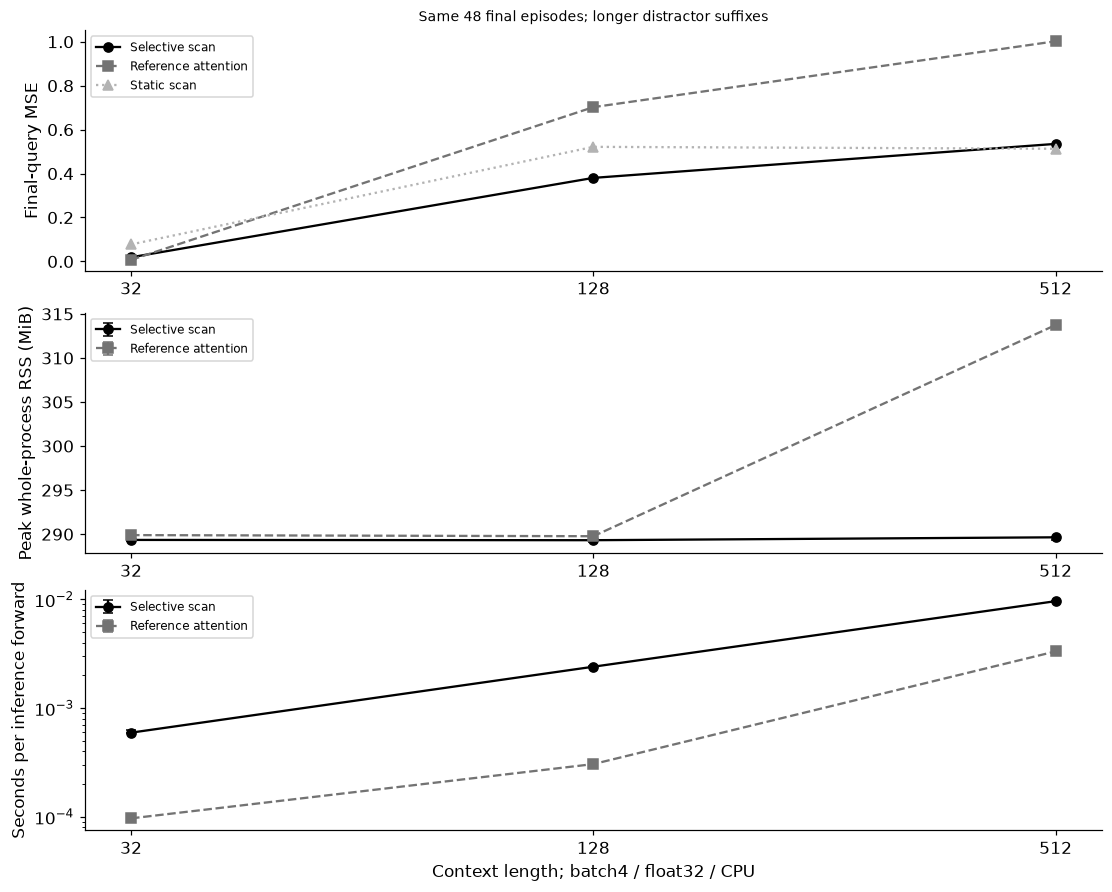

In [4]:
fig,axes=plt.subplots(3,1,figsize=(10,8));styles={'Selective scan':('o-','black'),'Reference attention':('s--','.45'),'Static scan':('^:','.7')}
for name,(style,color) in styles.items():
    subset=[r for r in rows if r['model']==name];axes[0].plot([r['length'] for r in subset],[r['last_query_MSE'] for r in subset],style,color=color,label=name)
axes[0].set(xscale='log',ylabel='Final-query MSE',title='Same 48 final episodes; longer distractor suffixes');axes[0].legend(fontsize=8)
for name in ['Selective scan','Reference attention']:
    style,color=styles[name]
    for ax,key,scale,ylabel in [(axes[1],'peak_RSS_bytes',1024**2,'Peak whole-process RSS (MiB)'),(axes[2],'seconds_per_forward',1,'Seconds per inference forward')]:
        lengths_profile=[];medians=[];lower=[];upper=[]
        for length in [32,128,512]:
            observed=np.array([r[key]/scale for r in resource_profile if r['model']==name and r['length']==length]);median=float(np.median(observed));lengths_profile.append(length);medians.append(median);lower.append(median-observed.min());upper.append(observed.max()-median)
        ax.errorbar(lengths_profile,medians,yerr=np.array([lower,upper]),fmt=style,color=color,capsize=3,label=name);ax.set(xscale='log',ylabel=ylabel);ax.legend(fontsize=8)
axes[-1].set(yscale='log',xlabel='Context length; batch4 / float32 / CPU')
for ax in axes:ax.set_xticks([32,128,512],labels=['32','128','512']);ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
plt.show()
assert all(np.isfinite(r['last_query_MSE']) for r in rows)


In [5]:
summary={'example_id':'code_112','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual input-dependent diagonal state model', 'exact diagonal discretization', 'paired context-length assessment', 'reference attention comparison', 'untrained summary-attention hybrid contract', 'measured CPU inference resources'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual input-dependent diagonal state model", "exact diagonal discretization", "paired context-length assessment", "reference attention comparison", "untrained summary-attention hybrid contract", "measured CPU inference resources"], "elapsed_seconds": 20.022, "example_id": "code_112", "hardware": "Darwin arm64 CPU", "resource_observations": [{"baseline_RSS_bytes": 299892736, "batch": 4, "dtype": "float32", "length": 32, "model": "Selective scan", "parameters": 627, "peak_RSS_bytes": 303398912, "platform": "Darwin", "replicate": 0, "seconds_per_forward": 0.0005938334012171254, "threads": 1, "timed_forwards": 5}, {"baseline_RSS_bytes": 299941888, "batch": 4, "dtype": "float32", "length": 32, "model": "Selective scan", "parameters": 627, "peak_RSS_bytes": 303415296, "platform": "Darwin", "replicate": 1, "seconds_per_forward": 0.0005901833996176719, "threads": 1, "timed_forwards": 5}, {"baseline_RSS_bytes": 299843584, "batch": 4, "dtype": 